# Agentic Portfolio Decomposition

In [1]:
# def get_tickers():
#     """Interactively ask the user for a target ticker and its component tickers.

#     The target is the asset whose returns we later want to decompose (e.g. a
#     fund or ETF); the components are the assets we will try to explain it with.

#     Input rules:
#         - Tickers are stripped of whitespace and upper-cased, so " aapl" and
#           "AAPL" are treated as the same symbol.
#         - Components are entered as one comma-separated line, e.g. "AAPL, MSFT, NVDA".
#         - Duplicate components are dropped (first occurrence kept, order preserved).
#         - The target is removed from the components, since explaining an asset
#           with itself would make the decomposition trivial.
#         - Empty answers are rejected and the question is asked again.

#     Args:
#         None.

#     Returns:
#         tuple[str, list[str]]: ``(target, components)`` where ``target`` is the
#         target ticker and ``components`` is a non-empty list of component tickers.

#     Raises:
#         None directly. Interrupting the prompt (e.g. stopping the kernel) raises
#         ``KeyboardInterrupt`` from ``input()``.

#     Side effects:
#         Reads from standard input and prints messages when an answer is rejected.
#     """
#     # Keep asking until we get a non-empty target ticker.
#     target = ""
#     while not target:
#         target = input("Target ticker: ").strip().upper()
#         if not target:
#             print("Please enter a target ticker.")

#     # Keep asking until at least one valid component (other than the target) remains.
#     components = []
#     while not components:
#         raw = input("Component tickers (comma-separated): ")
#         # dict.fromkeys de-duplicates while preserving the order the user typed.
#         cleaned = dict.fromkeys(t.strip().upper() for t in raw.split(","))
#         components = [t for t in cleaned if t and t != target]
#         if not components:
#             print("Please enter at least one component ticker different from the target.")

#     return target, components

In [2]:
# # Ask for the tickers once and keep them for the later analysis cells.
# target_ticker, component_tickers = get_tickers()
# print(f"Target: {target_ticker}")
# print(f"Components: {component_tickers}")

In [3]:
# Hard-coded tickers for now (stand-in for the interactive get_tickers() above).
# target_ticker: the asset whose returns we want to decompose.
# component_tickers: the assets used to explain the target.
target_ticker = 'FCNTX'
component_tickers = ['TLT', 'IEF', 'SPY', 'QQQ', 'GLD', 'USO']

In [4]:
import warnings

import pandas as pd
import yfinance as yf

# yfinance keeps small caches (timezones, cookies). Point them at the project's
# .cache/ folder so nothing is written outside this project.
yf.set_tz_cache_location(".cache/yfinance")


def get_close_prices(target, components, years=10):
    """Download daily closing prices for the target and component tickers.

    Prices come from Yahoo Finance via yfinance. Closes are *adjusted* for
    splits and dividends (``auto_adjust=True``), which is what return-based
    analysis needs: a raw close drops on every dividend date even though the
    holder lost nothing.

    Args:
        target (str): Target ticker, e.g. ``'SPY'``.
        components (list[str]): Component tickers. If the target also appears
            here it is only downloaded once.
        years (int): How many years of history to fetch, counting back from
            today. Defaults to 10.

    Returns:
        pandas.DataFrame: One column per ticker (target first, then components
        in the given order), indexed by trading date. Not yet cleaned, so it
        may contain NaN values.

    Raises:
        ValueError: If Yahoo returns no data at all, or no data for some ticker
            (usually a typo or a delisted symbol).

    Side effects:
        Makes network requests to Yahoo Finance and writes yfinance's cache
        files under ``.cache/yfinance``.
    """
    # Target first, then components; dict.fromkeys removes duplicates
    # (e.g. SPY as both target and component) while keeping the order.
    tickers = list(dict.fromkeys([target, *components]))

    # yfinance still uses pandas' deprecated inplace=... arguments internally,
    # which floods the output with Pandas4Warning. Those are yfinance's issue,
    # not ours, so hide only that warning type and only during the download.
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=pd.errors.Pandas4Warning)
        data = yf.download(
            tickers,
            period=f"{years}y",
            interval="1d",
            auto_adjust=True,
            progress=False,
        )
    if data is None or data.empty:
        raise ValueError(f"No price data returned for {tickers}.")

    # yf.download returns columns like ('Close', 'SPY'); keep only the closes
    # and put the columns back in our ticker order.
    prices = data["Close"].reindex(columns=tickers)

    missing = [t for t in tickers if prices[t].isna().all()]
    if missing:
        raise ValueError(f"No price data returned for: {missing}")
    return prices


def clean_prices(prices):
    """Clean a price table so every ticker has a value on every date.

    Rules:
        1. Sort by date and drop duplicate dates (keeping the last), so
           "fill forward" really means "from the previous trading day".
        2. Drop dates where every ticker is missing; those are not real
           trading days for this set of tickers.
        3. Forward-fill gaps: a missing price is replaced by that ticker's last
           known price (e.g. a holiday on one exchange, or a missing quote).
        4. Drop any leading rows that are still incomplete. Forward-filling
           cannot fill a gap *before* a ticker's first price, and inventing a
           value there would be wrong.

    Args:
        prices (pandas.DataFrame): Raw prices, one column per ticker, indexed
            by date (as returned by ``get_close_prices``).

    Returns:
        pandas.DataFrame: Cleaned copy with no missing values. The input is not
        modified.
    """
    cleaned = prices.sort_index()
    cleaned = cleaned[~cleaned.index.duplicated(keep="last")]
    cleaned = cleaned.dropna(how="all")
    cleaned = cleaned.ffill()
    return cleaned.dropna()

In [5]:
# Download 10 years of daily closes, then clean them (forward-fill gaps).
raw_prices = get_close_prices(target_ticker, component_tickers, years=10)
prices = clean_prices(raw_prices)

print(f"Missing values before cleaning: {int(raw_prices.isna().sum().sum())}, after: {int(prices.isna().sum().sum())}")
print(f"{len(prices)} trading days from {prices.index[0].date()} to {prices.index[-1].date()}")
prices.tail()

Missing values before cleaning: 1, after: 0
2513 trading days from 2016-11-03 to 2026-11-03


Ticker,FCNTX,TLT,IEF,SPY,QQQ,GLD,USO
Date,,,,,,,
2026-10-28,27.299999,80.989998,90.849998,772.309998,725.609985,373.510010,166.570007
2026-10-29,27.250000,81.489998,91.250000,769.359985,715.340027,368.570007,168.190002
2026-10-30,26.709999,81.839996,91.760002,755.719971,690.489990,355.779999,168.830002
2026-11-02,26.580000,81.730003,91.500000,752.099976,681.090027,361.649994,156.869995
2026-11-03,26.580000,81.139999,91.180000,755.049988,686.117981,359.915009,157.140396


In [6]:
def to_daily_returns(prices):
    """Convert closing prices to simple daily returns.

    Formula: r_t = P_t / P_{t-1} - 1 for each ticker. The first date has no
    previous close, so its row would be all NaN and is dropped.

    Args:
        prices (pandas.DataFrame): Cleaned closing prices, one column per
            ticker, indexed by date, with no missing values.

    Returns:
        pandas.DataFrame: Daily returns with the same columns, indexed by every
        date of ``prices`` except the first. Values are fractions
        (0.01 means +1%).
    """
    return prices.pct_change().iloc[1:]


def check_returns(prices, returns):
    """Check that compounded daily returns reproduce the price change.

    Simple returns compound multiplicatively, so over the whole period
        prod(1 + r_t) - 1  ==  P_last / P_first - 1
    for each ticker. Any difference beyond floating-point noise would mean the
    returns were computed on the wrong dates or rows went missing.

    Args:
        prices (pandas.DataFrame): The prices the returns were computed from.
        returns (pandas.DataFrame): Output of ``to_daily_returns(prices)``.

    Returns:
        pandas.DataFrame: One row per ticker with the compounded return, the
        price change over the same dates, and their difference (``delta``).
    """
    compounded = (1 + returns).prod() - 1
    price_change = prices.iloc[-1] / prices.iloc[0] - 1
    return pd.DataFrame({
        "compounded_returns": compounded,
        "price_change": price_change,
        "delta": compounded - price_change,
    })


returns = to_daily_returns(prices)
check = check_returns(prices, returns)

print(f"Returns from {returns.index[0].date()} to {returns.index[-1].date()} "
      f"({len(returns)} days), prices from {prices.index[0].date()}")
print(check.to_string(float_format=lambda x: f"{x:.6e}" if abs(x) < 1e-4 else f"{x:.4%}"))

Returns from 2016-11-04 to 2026-11-03 (2512 days), prices from 2016-11-03
        compounded_returns  price_change         delta
Ticker                                                
FCNTX            419.1750%     419.1750%  0.000000e+00
TLT              -17.3437%     -17.3437%  1.221245e-15
IEF                4.7138%       4.7138% -3.330669e-15
SPY              323.4784%     323.4784%  7.993606e-15
QQQ              543.7598%     543.7598%  3.375078e-14
GLD              189.5535%     189.5535%  1.154632e-14
USO               94.8666%      94.8666% -4.662937e-15


In [7]:
# Window lengths, in trading days (rows of the returns DataFrame).
lookback = 120    # days of history used for each estimate
projection = 30   # days ahead to project

In [8]:
import numpy as np


def rolling_regression(returns, target, components, lookback, projection):
    """Walk forward through the returns, fitting and testing a regression.

    For each start row i (stepping one trading day at a time):
        1. Fit:  ordinary least squares of the target's returns on the
           components' returns over rows [i, i + lookback), with an intercept:
               target_t = a + b_1 * comp1_t + ... + b_k * compk_t + error
        2. Project: for the next ``projection`` rows
           [i + lookback, i + lookback + projection), predict the target's
           return as  a + sum(b_j * comp_j_t)  using the fitted weights.
        3. Record: the correlation between those predictions and the actual
           target returns, plus the 1-day result (the prediction and the actual
           return on the first day after the lookback window).

    The weights only ever use rows strictly before the days they predict, so
    there is no look-ahead. The loop stops at the last start row that still has
    a full ``projection`` window after it, so every correlation uses the same
    number of days.

    Args:
        returns (pandas.DataFrame): Daily returns, one column per ticker,
            indexed by date, with no missing values.
        target (str): Column name of the target ticker.
        components (list[str]): Column names of the component tickers.
        lookback (int): Rows used to fit each regression.
        projection (int): Rows predicted with each set of weights.

    Returns:
        pandas.DataFrame: One row per window, indexed by the first projected
        date (the day after the lookback ends), with columns:
            - ``correlation``: correlation of predicted vs actual target
              returns over the projection window.
            - ``predicted_1d``: predicted target return on the index date.
            - ``actual_1d``: actual target return on the index date.

    Raises:
        ValueError: If there are fewer than ``lookback + projection`` rows.
    """
    n_windows = len(returns) - lookback - projection + 1
    if n_windows < 1:
        raise ValueError(
            f"Need at least lookback + projection = {lookback + projection} rows, "
            f"got {len(returns)}."
        )

    y_all = returns[target].to_numpy()
    # Prepend a column of ones so the first fitted weight is the intercept.
    X_all = np.column_stack([np.ones(len(returns)), returns[components].to_numpy()])

    dates, correlations, predicted_1d, actual_1d = [], [], [], []
    for i in range(n_windows):
        fit = slice(i, i + lookback)
        proj = slice(i + lookback, i + lookback + projection)

        # Least-squares weights [intercept, b_1, ..., b_k] for this lookback window.
        weights, *_ = np.linalg.lstsq(X_all[fit], y_all[fit], rcond=None)

        predicted = X_all[proj] @ weights
        actual = y_all[proj]

        dates.append(returns.index[i + lookback])
        correlations.append(np.corrcoef(predicted, actual)[0, 1])
        predicted_1d.append(predicted[0])
        actual_1d.append(actual[0])

    return pd.DataFrame(
        {"correlation": correlations, "predicted_1d": predicted_1d, "actual_1d": actual_1d},
        index=pd.DatetimeIndex(dates, name="Date"),
    )


results = rolling_regression(returns, target_ticker, component_tickers, lookback, projection)
print(f"{len(results)} windows, first projected day {results.index[0].date()}, "
      f"last {results.index[-1].date()}")
print(f"Mean rolling correlation: {results['correlation'].mean():.3f}")
results.tail()

2363 windows, first projected day 2017-05-01, last 2026-09-23
Mean rolling correlation: 0.958


,correlation,predicted_1d,actual_1d
Date,,,
2026-09-17,0.919985,0.012780,0.014200
2026-09-18,0.915138,0.001011,0.000737
2026-09-21,0.926577,0.017759,0.020619
2026-09-22,0.913606,0.000872,0.005051
2026-09-23,0.912739,-0.009263,-0.009332


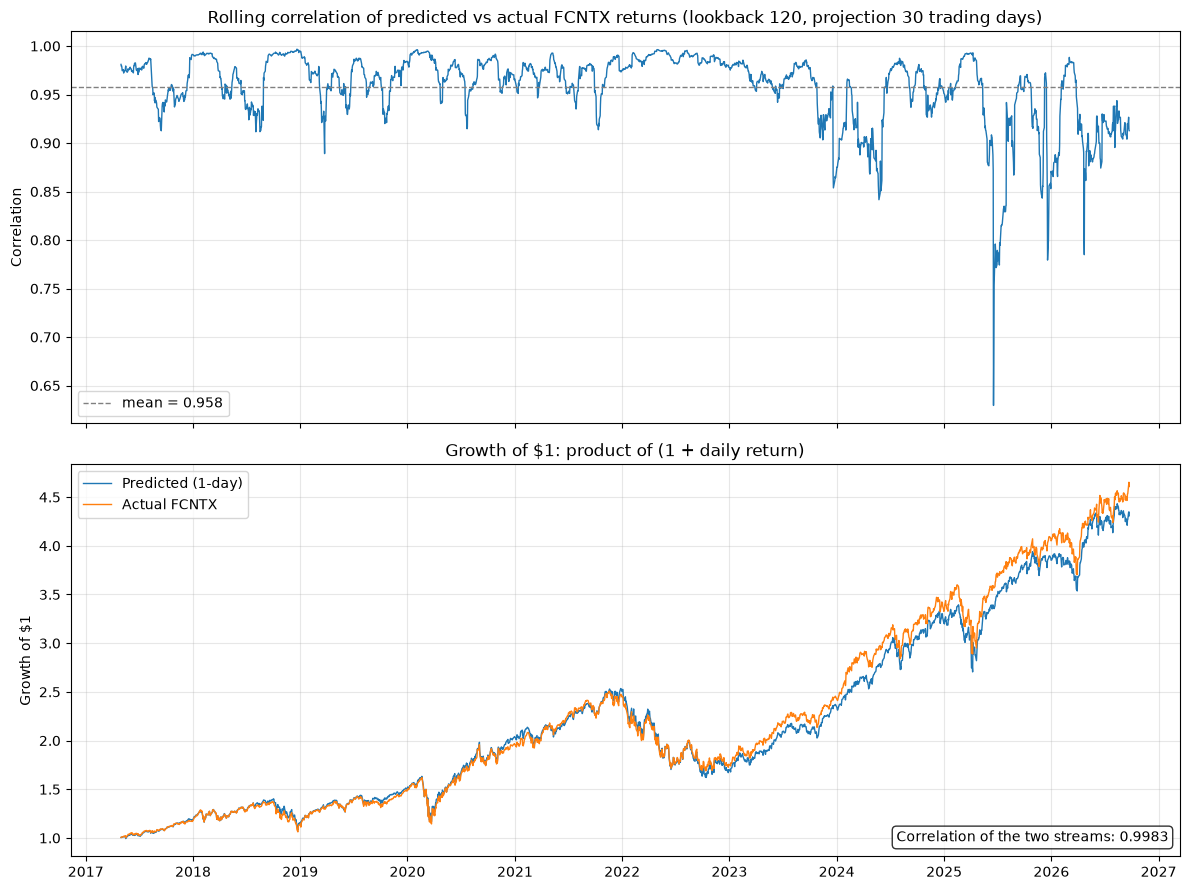

In [9]:
import matplotlib.pyplot as plt

# Growth of $1: compound the 1-day returns, i.e. the running product of (1 + r).
predicted_growth = (1 + results["predicted_1d"]).cumprod()
actual_growth = (1 + results["actual_1d"]).cumprod()
# Correlation of the two price (growth) streams, shown on the second chart.
stream_corr = predicted_growth.corr(actual_growth)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 9), sharex=True)

# Chart 1: how well each lookback's weights track the target over the next
# `projection` days, dated by the first projected day.
ax1.plot(results.index, results["correlation"], lw=1)
ax1.axhline(results["correlation"].mean(), color="gray", ls="--", lw=1,
            label=f"mean = {results['correlation'].mean():.3f}")
ax1.set_title(f"Rolling correlation of predicted vs actual {target_ticker} returns "
              f"(lookback {lookback}, projection {projection} trading days)")
ax1.set_ylabel("Correlation")
ax1.legend(loc="lower left")
ax1.grid(alpha=0.3)

# Chart 2: growth of $1 from the 1-day-ahead predictions vs the actual target.
ax2.plot(predicted_growth.index, predicted_growth, lw=1, label="Predicted (1-day)")
ax2.plot(actual_growth.index, actual_growth, lw=1, label=f"Actual {target_ticker}")
ax2.set_title("Growth of $1: product of (1 + daily return)")
ax2.set_ylabel("Growth of $1")
ax2.legend(loc="upper left")
ax2.grid(alpha=0.3)
ax2.text(0.99, 0.03, f"Correlation of the two streams: {stream_corr:.4f}",
         transform=ax2.transAxes, ha="right", va="bottom",
         bbox=dict(boxstyle="round", fc="white", alpha=0.8))

fig.tight_layout()
plt.show()

Train: 2016-11-04 to 2024-10-30 (2009 days)
Test:  2024-10-31 to 2026-11-03 (503 days)
Weights: intercept 0.0000, TLT 0.0522, IEF -0.1766, SPY 0.3665, QQQ 0.5778, GLD 0.0282, USO 0.0072


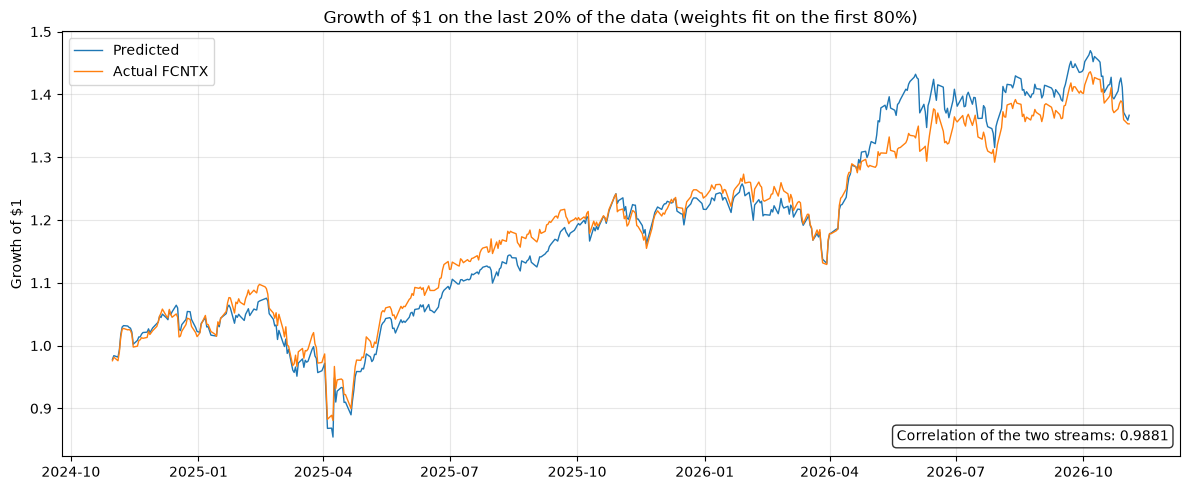

In [10]:
# Single train/test split: fit once on the first 80% of the returns, then
# predict the last 20% with those fixed weights (no refitting).
train_frac = 0.8
split = int(len(returns) * train_frac)
train, test = returns.iloc[:split], returns.iloc[split:]

# OLS with an intercept, same model as the rolling regression:
#   target_t = a + b_1 * comp1_t + ... + b_k * compk_t + error
X_train = np.column_stack([np.ones(len(train)), train[component_tickers].to_numpy()])
weights, *_ = np.linalg.lstsq(X_train, train[target_ticker].to_numpy(), rcond=None)

# Predicted target returns on the test rows, from the component returns only.
X_test = np.column_stack([np.ones(len(test)), test[component_tickers].to_numpy()])
test_predicted = pd.Series(X_test @ weights, index=test.index)

# Convert returns to price streams: expanding product of (1 + r), starting from 1.
split_predicted_growth = (1 + test_predicted).cumprod()
split_actual_growth = (1 + test[target_ticker]).cumprod()
split_corr = split_predicted_growth.corr(split_actual_growth)

print(f"Train: {train.index[0].date()} to {train.index[-1].date()} ({len(train)} days)")
print(f"Test:  {test.index[0].date()} to {test.index[-1].date()} ({len(test)} days)")
print("Weights:", ", ".join(f"{name} {w:.4f}"
                            for name, w in zip(["intercept", *component_tickers], weights)))

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(split_predicted_growth.index, split_predicted_growth, lw=1, label="Predicted")
ax.plot(split_actual_growth.index, split_actual_growth, lw=1, label=f"Actual {target_ticker}")
ax.set_title(f"Growth of $1 on the last {1 - train_frac:.0%} of the data "
             f"(weights fit on the first {train_frac:.0%})")
ax.set_ylabel("Growth of $1")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)
ax.text(0.99, 0.03, f"Correlation of the two streams: {split_corr:.4f}",
        transform=ax.transAxes, ha="right", va="bottom",
        bbox=dict(boxstyle="round", fc="white", alpha=0.8))
fig.tight_layout()
plt.show()